In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

In [2]:
df = pd.read_csv("Iris.csv")

# Признаки, по которым модель будет определять вид цветка
X = df.drop(columns=["species"])

# Целевая переменная — вид цветка
y = df["species"]

# Разделяем данные: 80% для обучения, 20% для тестирования
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)
print("Названия признаков:", list(X.columns))

Размер обучающей выборки: (120, 4)
Размер тестовой выборки: (30, 4)
Названия признаков: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']


In [3]:
# Создаём модель одиночного дерева
tree_model = DecisionTreeClassifier(random_state=42)

# Обучаем модель
tree_model.fit(X_train, y_train)

# Делаем прогноз на тестовых данных
tree_predictions = tree_model.predict(X_test)

# Считаем метрики
tree_accuracy = accuracy_score(y_test, tree_predictions)
tree_f1 = f1_score(y_test, tree_predictions, average="macro")

print("Decision Tree")
print("Accuracy:", round(tree_accuracy, 4))
print("F1-score:", round(tree_f1, 4))

Decision Tree
Accuracy: 0.9333
F1-score: 0.9333


In [4]:
# Создаём случайный лес из 100 деревьев
forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Обучаем модель на тех же данных
forest_model.fit(X_train, y_train)

# Делаем прогноз
forest_predictions = forest_model.predict(X_test)

# Считаем метрики
forest_accuracy = accuracy_score(y_test, forest_predictions)
forest_f1 = f1_score(y_test, forest_predictions, average="macro")

print("Random Forest")
print("Accuracy:", round(forest_accuracy, 4))
print("F1-score:", round(forest_f1, 4))

Random Forest
Accuracy: 0.9
F1-score: 0.8997


In [5]:
results = pd.DataFrame({
    "Модель": ["Decision Tree", "Random Forest"],
    "Accuracy": [tree_accuracy, forest_accuracy],
    "F1-score": [tree_f1, forest_f1]
})

print(results.round(4).to_string(index=False))

       Модель  Accuracy  F1-score
Decision Tree    0.9333    0.9333
Random Forest    0.9000    0.8997


In [6]:
importance = pd.DataFrame({
    "Признак": X.columns,
    "Важность": forest_model.feature_importances_
})

importance = importance.sort_values(
    by="Важность",
    ascending=False
)

print(importance.round(4).to_string(index=False))

     Признак  Важность
 petal_width    0.4372
petal_length    0.4315
sepal_length    0.1163
 sepal_width    0.0150


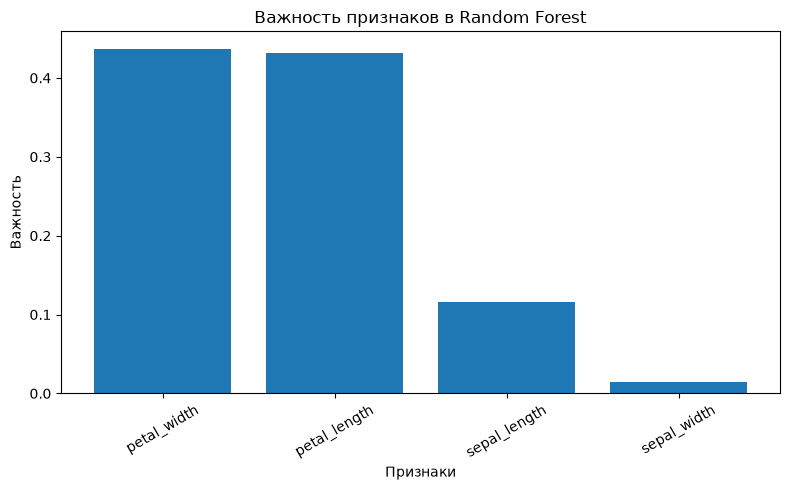

In [7]:
plt.figure(figsize=(8, 5))

plt.bar(
    importance["Признак"],
    importance["Важность"]
)

plt.title("Важность признаков в Random Forest")
plt.xlabel("Признаки")
plt.ylabel("Важность")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Вывод

В данной практической работе были обучены две модели классификации: Decision Tree и Random Forest. Обе модели обучались на одной и той же обучающей выборке, а качество оценивалось на тестовой выборке с помощью метрик Accuracy и F1-score.

Результаты моделей были сравнены в таблице. Случайный лес состоит из 100 деревьев решений и объединяет их предсказания.

Наиболее важные признаки определены с помощью `feature_importances_` и представлены на столбчатой диаграмме.

Два наиболее важных признака: **укажи два признака с наибольшими значениями из полученной таблицы**.

По результатам эксперимента модель с более высокими значениями метрик показала лучшее качество классификации на тестовой выборке.